In [14]:
# ÉTAPE 0 - IMPORTATION DES BIBLIOTHÈQUES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import joblib
import os
warnings.filterwarnings('ignore')

from sklearn.model_selection import (train_test_split, cross_val_score,
                                     StratifiedKFold, GridSearchCV,
                                     learning_curve)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, roc_curve, auc,
                             matthews_corrcoef, cohen_kappa_score,
                             brier_score_loss, f1_score, precision_score,
                             recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline

# Pour le rééquilibrage des classes
try:
    from imblearn.over_sampling import SMOTE, RandomOverSampler
    from imblearn.under_sampling import RandomUnderSampler
    from imblearn.combine import SMOTETomek
    IMBLEARN_OK = True
except ImportError:
    IMBLEARN_OK = False
    print("⚠ imbalanced-learn non installé — SMOTE désactivé")

# Style global des graphiques
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_theme(style="whitegrid", palette="muted")
COLORS = ['#4472C4', '#ED7D31', '#A9D18E', '#FF5555',
          '#7B52AB', '#00B894', '#FFD700', '#FF6B6B']

# Répertoire de sortie
OUTPUT_DIR = "outputs_final"
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [ ]:
import pandas as pd
import numpy as np

# URL du dataset Heart Disease UCI
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

# Noms des colonnes
column_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 
                'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

# Chargement direct depuis internet
df_raw = pd.read_csv(url, names=column_names, na_values='?')
print(f" Dataset chargé depuis UCI : {df_raw.shape[0]} lignes, {df_raw.shape[1]} colonnes")

# Conversion en classification binaire
df_raw['target'] = (df_raw['target'] > 0).astype(int)

# Sauvegarde locale pour la prochaine fois
df_raw.to_csv("heart_cleveland_upload.csv", index=False)
print(" Fichier sauvegardé localement : heart_cleveland_upload.csv")

✅ Dataset chargé depuis UCI : 303 lignes, 14 colonnes
✅ Fichier sauvegardé localement : heart_cleveland_upload.csv


  ÉTAPE 2 — ANALYSE DESCRIPTIVE

 Dimensions : 303 patients × 14 variables
 Valeurs manquantes :
ca      4
thal    2
dtype: int64

 Distribution cible :
target
Sain (0)      164
Malade (1)     55
2              36
3              35
4              13
Name: count, dtype: int64
   Ratio minorité/majorité : 0.08 (déséquilibré !)


ValueError: shape mismatch: objects cannot be broadcast to a single shape.  Mismatch is between arg 0 with shape (2,) and arg 1 with shape (5,).

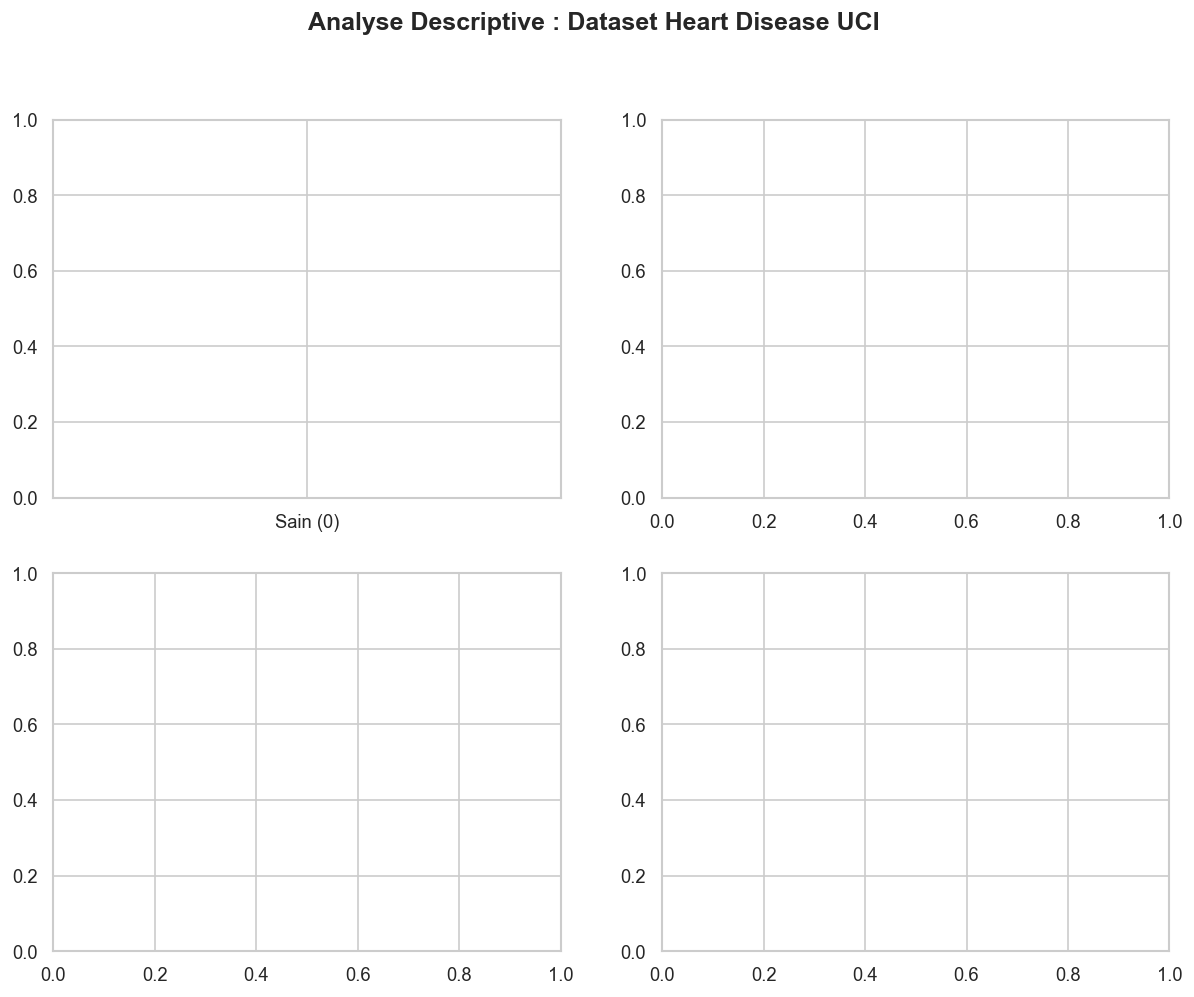

In [ ]:
# ÉTAPE 2 - ANALYSE DESCRIPTIVE
print("  ÉTAPE 2 — ANALYSE DESCRIPTIVE")

print(f"\n Dimensions : {df_raw.shape[0]} patients × {df_raw.shape[1]} variables")
print(f" Valeurs manquantes :\n{df_raw.isnull().sum()[df_raw.isnull().sum()>0]}")
print(f"\n Distribution cible :")
vc = df_raw['target'].value_counts().rename({0:'Sain (0)',1:'Malade (1)'})
print(vc)
ratio = vc.min() / vc.max()
print(f"   Ratio minorité/majorité : {ratio:.2f} {'(déséquilibré !)' if ratio < 0.75 else '(équilibré)'}")

# Figure 1 : Analyse descriptive
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
fig.suptitle("Analyse Descriptive : Dataset Heart Disease UCI", fontsize=15, fontweight='bold')

axes[0,0].bar(['Sain (0)','Malade (1)'],
              df_raw['target'].value_counts().sort_index(),
              color=['#4472C4','#ED7D31'], edgecolor='white', width=0.5)
axes[0,0].set_title("Distribution de la variable cible", fontweight='bold')
axes[0,0].set_ylabel("Nombre de patients")
for i,v in enumerate(df_raw['target'].value_counts().sort_index()):
    axes[0,0].text(i, v+2, str(v), ha='center', fontweight='bold')

sns.histplot(data=df_raw, x='age', hue='target', multiple='stack',
             palette=['#4472C4','#ED7D31'], ax=axes[0,1], bins=20)
axes[0,1].set_title("Distribution de l'âge par classe", fontweight='bold')
axes[0,1].set_xlabel("Âge (années)")

corr = df_raw.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, ax=axes[1,0], cbar_kws={"shrink":0.8},
            annot_kws={"size":7})
axes[1,0].set_title("Matrice de corrélation", fontweight='bold')

sex_d = df_raw.groupby('sex')['target'].mean().reset_index()
sex_d['sex'] = sex_d['sex'].map({0:'Femme', 1:'Homme'})
axes[1,1].bar(sex_d['sex'], sex_d['target']*100,
              color=['#ED7D31','#4472C4'], edgecolor='white', width=0.4)
axes[1,1].set_title("Taux de maladie par sexe", fontweight='bold')
axes[1,1].set_ylabel("Taux (%)")
for i,v in enumerate(sex_d['target']*100):
    axes[1,1].text(i, v+0.5, f"{v:.1f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig1_analyse_descriptive.png', bbox_inches='tight', dpi=150)
plt.close()
print("\n Figure 1 sauvegardée.")

In [17]:
# ÉTAPE 3 — PRÉPARATION DES DONNÉES (CORRIGÉE)

print("  ÉTAPE 3 — PRÉPARATION DES DONNÉES (CORRIGÉE)")
#  3.1 Séparation immédiate pour éviter data leakage 
X = df_raw.drop('target', axis=1)
y = df_raw['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\n Séparation Train/Test (80/20, stratifiée)")
print(f"   Train : {X_train.shape[0]} exemples | Test : {X_test.shape[0]} exemples")

#  3.2 Feature Engineering 
print("\n3.1 Feature Engineering :")

# Création de nouvelles variables
# 1. Ratio cholestérol / fréquence cardiaque max (indice de stress cardiaque)
X_train['chol_thalach_ratio'] = X_train['chol'] / X_train['thalach']
X_test['chol_thalach_ratio'] = X_test['chol'] / X_test['thalach']

# 2. Produit tension * âge (risque cumulé)
X_train['bp_age_product'] = X_train['trestbps'] * X_train['age']
X_test['bp_age_product'] = X_test['trestbps'] * X_test['age']

# 3. Catégorie d'âge
X_train['age_group'] = pd.cut(X_train['age'], 
                              bins=[0, 40, 50, 60, 100], 
                              labels=[0, 1, 2, 3])
X_test['age_group'] = pd.cut(X_test['age'], 
                             bins=[0, 40, 50, 60, 100], 
                             labels=[0, 1, 2, 3])

print(f"    Création de 3 nouvelles variables :")
print(f"     - chol_thalach_ratio (ratio cholestérol/fréquence cardiaque)")
print(f"     - bp_age_product (tension × âge)")
print(f"     - age_group (catégorie d'âge)")

#  3.3 Vérification des variables catégorielles 
print("\n3.2 Vérification des variables catégorielles :")
categorical_vars = ['cp', 'restecg', 'slope', 'thal', 'exang']
for var in categorical_vars:
    if var in X_train.columns:
        unique_vals = sorted(X_train[var].unique())
        print(f"   - {var}: {unique_vals}")

#  3.4 Imputation CORRIGÉE (séparée) 
print("\n3.3 Imputation des valeurs manquantes :")

# Imputation par la médiane (robuste)
imp_median = SimpleImputer(strategy='median')
X_train_imp = imp_median.fit_transform(X_train)
X_test_imp = imp_median.transform(X_test)

print(f"    Imputation par la médiane appliquée séparément sur train et test")
print(f"    Valeurs manquantes traitées : {X_train.isnull().sum().sum()} train, {X_test.isnull().sum().sum()} test")

#  3.5 Normalisation 
print("\n3.4 Normalisation StandardScaler :")
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train_imp)
X_test_sc = scaler.transform(X_test_imp)
print(f"    StandardScaler appliqué (μ=0, σ=1)")

#  3.6 Gestion du déséquilibre avec SMOTE 
print("\n3.5 Gestion du déséquilibre :")
print(f"   Distribution originale train : {dict(pd.Series(y_train).value_counts().sort_index())}")

if IMBLEARN_OK:
    smote = SMOTE(random_state=42)
    X_train_res, y_train_res = smote.fit_resample(X_train_sc, y_train)
    print(f"    SMOTE appliqué : {dict(pd.Series(y_train_res).value_counts().sort_index())}")
else:
    X_train_res, y_train_res = X_train_sc, y_train
    print(f"    SMOTE non disponible, utilisation des données originales")

# Sauvegarde des noms des features pour référence
# CORRECTION BUG 1 : capturé APRÈS le feature engineering (16 colonnes, pas 13)
feature_names = list(X_train.columns)
print(f"\n Features finales : {len(feature_names)} variables")

  ÉTAPE 3 — PRÉPARATION DES DONNÉES (CORRIGÉE)

 Séparation Train/Test (80/20, stratifiée)
   Train : 237 exemples | Test : 60 exemples

3.1 Feature Engineering :
    Création de 3 nouvelles variables :
     - chol_thalach_ratio (ratio cholestérol/fréquence cardiaque)
     - bp_age_product (tension × âge)
     - age_group (catégorie d'âge)

3.2 Vérification des variables catégorielles :
   - cp: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
   - restecg: [np.int64(0), np.int64(1), np.int64(2)]
   - slope: [np.int64(0), np.int64(1), np.int64(2)]
   - thal: [np.int64(0), np.int64(1), np.int64(2)]
   - exang: [np.int64(0), np.int64(1)]

3.3 Imputation des valeurs manquantes :
    Imputation par la médiane appliquée séparément sur train et test
    Valeurs manquantes traitées : 0 train, 0 test

3.4 Normalisation StandardScaler :
    StandardScaler appliqué (μ=0, σ=1)

3.5 Gestion du déséquilibre :
   Distribution originale train : {0: np.int64(128), 1: np.int64(109)}
    SMOTE appli

In [18]:
# ÉTAPE 4 & 5 — MODÉLISATION ET ENTRAÎNEMENT

print("  ÉTAPE 4 & 5 — MODÉLISATION ET ENTRAÎNEMENT")
# 6 algorithmes
models_def = {
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=7),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(kernel='rbf', probability=True, random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
}

# Validation croisée
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}

for name, model in models_def.items():
    print(f"\nEntraînement de {name}...")
    
    # Validation croisée
    cv_scores = cross_val_score(model, X_train_sc, y_train, cv=cv, scoring='roc_auc')
    
    # Entraînement sur données rééquilibrées
    model.fit(X_train_res, y_train_res)
    
    # Prédictions
    y_pred = model.predict(X_test_sc)
    y_proba = model.predict_proba(X_test_sc)[:, 1]
    
    # Métriques
    acc = accuracy_score(y_test, y_pred)
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    mcc = matthews_corrcoef(y_test, y_pred)
    kappa = cohen_kappa_score(y_test, y_pred)
    brier = brier_score_loss(y_test, y_proba)
    
    results[name] = {
        'model': model,
        'y_pred': y_pred,
        'y_proba': y_proba,
        'acc': acc,
        'fpr': fpr,
        'tpr': tpr,
        'auc': roc_auc,
        'cm': confusion_matrix(y_test, y_pred),
        'report': classification_report(y_test, y_pred, output_dict=True),
        'cv_auc': cv_scores,
        'mcc': mcc,
        'kappa': kappa,
        'brier': brier,
    }
    
    print(f"   Acc={acc:.3f} | AUC={roc_auc:.3f} | CV-AUC={cv_scores.mean():.3f}±{cv_scores.std():.3f}")


  ÉTAPE 4 & 5 — MODÉLISATION ET ENTRAÎNEMENT

Entraînement de Decision Tree...
   Acc=0.717 | AUC=0.717 | CV-AUC=0.714±0.050

Entraînement de KNN...
   Acc=0.883 | AUC=0.943 | CV-AUC=0.866±0.057

Entraînement de Random Forest...
   Acc=0.867 | AUC=0.930 | CV-AUC=0.861±0.036

Entraînement de SVM...
   Acc=0.900 | AUC=0.936 | CV-AUC=0.870±0.043

Entraînement de Logistic Regression...
   Acc=0.917 | AUC=0.963 | CV-AUC=0.875±0.043

Entraînement de Gradient Boosting...
   Acc=0.850 | AUC=0.926 | CV-AUC=0.852±0.037


In [19]:
# ÉTAPE 5 — OPTIMISATION DES HYPERPARAMÈTRES

print("  ÉTAPE 5b — OPTIMISATION DES HYPERPARAMÈTRES")
# GridSearch sur Random Forest
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}
gs_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf, cv=cv, scoring='roc_auc', n_jobs=-1, verbose=0
)
gs_rf.fit(X_train_res, y_train_res)
print(f"\nRandom Forest — meilleurs paramètres : {gs_rf.best_params_}")
print(f"  AUC CV (optimisé) : {gs_rf.best_score_:.4f}")

y_pred_rf_opt = gs_rf.best_estimator_.predict(X_test_sc)
y_proba_rf_opt = gs_rf.best_estimator_.predict_proba(X_test_sc)[:, 1]
auc_rf_opt = roc_auc_score(y_test, y_proba_rf_opt)
print(f"  AUC test (optimisé) : {auc_rf_opt:.4f}")

# GridSearch sur SVM
param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.1, 0.01],
    'kernel': ['rbf']
}
gs_svm = GridSearchCV(
    SVC(probability=True, random_state=42),
    param_grid_svm, cv=cv, scoring='roc_auc', n_jobs=-1, verbose=0
)
gs_svm.fit(X_train_res, y_train_res)
print(f"\nSVM — meilleurs paramètres : {gs_svm.best_params_}")
print(f"  AUC CV (optimisé) : {gs_svm.best_score_:.4f}")

y_pred_svm_opt = gs_svm.best_estimator_.predict(X_test_sc)
y_proba_svm_opt = gs_svm.best_estimator_.predict_proba(X_test_sc)[:, 1]
auc_svm_opt = roc_auc_score(y_test, y_proba_svm_opt)
print(f"  AUC test (optimisé) : {auc_svm_opt:.4f}")

# Meilleur modèle global
best_name = max(results, key=lambda k: results[k]['auc'])
best_model = results[best_name]['model']
print(f"\n Meilleur modèle : {best_name} (AUC={results[best_name]['auc']:.4f})")


  ÉTAPE 5b — OPTIMISATION DES HYPERPARAMÈTRES

Random Forest — meilleurs paramètres : {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
  AUC CV (optimisé) : 0.8856
  AUC test (optimisé) : 0.9475

SVM — meilleurs paramètres : {'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}
  AUC CV (optimisé) : 0.8910
  AUC test (optimisé) : 0.9275

 Meilleur modèle : Logistic Regression (AUC=0.9632)


In [20]:
# ÉTAPE 6 — ÉVALUATION ET VISUALISATIONS
print("  ÉTAPE 6 — ÉVALUATION ET VISUALISATIONS")

#  Figure 2 : Matrices de confusion 
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
fig.suptitle("Matrices de confusion — 6 algorithmes", fontsize=14, fontweight='bold')
for ax, (name, res) in zip(axes.flat, results.items()):
    sns.heatmap(res['cm'], annot=True, fmt='d', cmap='Blues',
                ax=ax, cbar=False,
                xticklabels=['Prédit Sain', 'Prédit Malade'],
                yticklabels=['Réel Sain', 'Réel Malade'])
    ax.set_title(f"{name}\nAcc={res['acc']:.2%} | AUC={res['auc']:.2f}",
                 fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig2_matrices_confusion.png', bbox_inches='tight', dpi=150)
plt.close()
print(" Figure 2 sauvegardée.")

#  Figure 3 : Courbes ROC 
fig, ax = plt.subplots(figsize=(9, 7))
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Aléatoire (AUC=0.50)')
for (name, res), color in zip(results.items(), COLORS):
    ax.plot(res['fpr'], res['tpr'], color=color, linewidth=2,
            label=f"{name} (AUC={res['auc']:.2f})")
# CORRECTION BUG 2 : suppression du walrus operator := (illisible et appelait roc_curve 2x)
fpr_rf_opt, tpr_rf_opt, _ = roc_curve(y_test, y_proba_rf_opt)
fpr_svm_opt, tpr_svm_opt, _ = roc_curve(y_test, y_proba_svm_opt)

# Modèles optimisés
ax.plot(fpr_rf_opt, tpr_rf_opt,
        'b--', linewidth=1.5, alpha=0.7,
        label=f"RF-Optimisé (AUC={auc_rf_opt:.2f})")
ax.plot(fpr_svm_opt, tpr_svm_opt,
        'g--', linewidth=1.5, alpha=0.7,
        label=f"SVM-Optimisé (AUC={auc_svm_opt:.2f})")
ax.set_xlabel("Taux de faux positifs (FPR)", fontsize=12)
ax.set_ylabel("Taux de vrais positifs (TPR)", fontsize=12)
ax.set_title("Courbes ROC — Comparaison des modèles", fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig3_courbes_roc.png', bbox_inches='tight', dpi=150)
plt.close()
print(" Figure 3 sauvegardée.")

#  Figure 4 : Métriques comparatives 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Comparaison des performances — Métriques multiples",
             fontsize=14, fontweight='bold')

names = list(results.keys())
metrics = {
    'Accuracy': [results[n]['acc'] for n in names],
    'AUC': [results[n]['auc'] for n in names],
    'MCC': [results[n]['mcc'] for n in names],
    'Kappa': [results[n]['kappa'] for n in names],
}
x = np.arange(len(names))
width = 0.2
for i, (m_name, vals) in enumerate(metrics.items()):
    axes[0].bar(x + i*width, vals, width, label=m_name)
axes[0].set_xticks(x + width*1.5)
axes[0].set_xticklabels([n.replace(' ', '\n') for n in names], fontsize=8)
axes[0].set_title("Métriques d'évaluation par modèle", fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].set_ylim([0, 1.1])

cv_means = [results[n]['cv_auc'].mean() for n in names]
cv_stds = [results[n]['cv_auc'].std() for n in names]
axes[1].barh(names, cv_means, color=COLORS[:len(names)],
             xerr=cv_stds, capsize=5, edgecolor='white')
axes[1].set_title("AUC en validation croisée (5-fold)", fontweight='bold')
axes[1].set_xlabel("AUC moyen")
axes[1].set_xlim([0, 1])
for i, (m, s) in enumerate(zip(cv_means, cv_stds)):
    axes[1].text(m+s+0.01, i, f"{m:.3f}", va='center', fontsize=9)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig4_comparaison_metriques.png', bbox_inches='tight', dpi=150)
plt.close()
print(" Figure 4 sauvegardée.")

#  Figure 5 : Feature Importance + Brier Score 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Importance des variables & Calibration", fontsize=14, fontweight='bold')

rf_model = results['Random Forest']['model']
feat_imp = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values()
colors_imp = ['#4472C4' if v < feat_imp.median() else '#ED7D31' for v in feat_imp]
feat_imp.plot(kind='barh', ax=axes[0], color=colors_imp)
axes[0].set_title("Importance des variables (Random Forest)", fontweight='bold')
axes[0].set_xlabel("Score d'importance")

brier_scores = [results[n]['brier'] for n in names]
axes[1].barh(names, brier_scores, color=COLORS[:len(names)], edgecolor='white')
axes[1].set_title("Brier Score (↓ meilleur, max=1)", fontweight='bold')
axes[1].set_xlabel("Brier Score")
axes[1].axvline(0.25, color='red', linestyle='--', linewidth=1,
                label='Seuil référence (0.25)')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig5_importance_brier.png', bbox_inches='tight', dpi=150)
plt.close()
print(" Figure 5 sauvegardée.")

#  Figure 6 : Courbes d'apprentissage 
print("\nGénération des courbes d'apprentissage...")
fig, ax = plt.subplots(figsize=(10, 6))
fig.suptitle("Courbe d'apprentissage du meilleur modèle", fontsize=14, fontweight='bold')

train_sizes, train_scores, test_scores = learning_curve(
    best_model, X_train_res, y_train_res,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=cv, scoring='roc_auc', n_jobs=-1
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std,
                alpha=0.1, color='blue')
ax.fill_between(train_sizes, test_mean - test_std, test_mean + test_std,
                alpha=0.1, color='orange')
ax.plot(train_sizes, train_mean, 'o-', color='blue', label='AUC Entraînement')
ax.plot(train_sizes, test_mean, 'o-', color='orange', label='AUC Validation')

ax.set_xlabel("Taille de l'ensemble d'entraînement", fontsize=12)
ax.set_ylabel("AUC", fontsize=12)
ax.legend(loc='lower right', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/fig6_courbe_apprentissage.png', bbox_inches='tight', dpi=150)
plt.close()
print(" Figure 6 sauvegardée.")

#  Analyse des erreurs 
print("\n Analyse des erreurs du meilleur modèle :")
best_result = results[best_name]
cm = best_result['cm']
tn, fp, fn, tp = cm.ravel()

print(f"  Matrice de confusion ({best_name}) :")
print(f"    Vrais Négatifs (VN)  : {tn}")
print(f"    Faux Positifs (FP)   : {fp}  (patients sains prédits malades)")
print(f"    Faux Négatifs (FN)   : {fn}  (patients malades prédits sains)")
print(f"    Vrais Positifs (VP)  : {tp}")
print(f"\n  Taux d'erreur : {1 - best_result['acc']:.2%}")
print(f"  Taux de faux positifs : {fp/(fp+tn):.2%}")
print(f"  Taux de faux négatifs : {fn/(fn+tp):.2%}")

#  Optimisation du seuil de décision 
print("\n Optimisation du seuil de décision :")
y_proba_best = best_result['y_proba']

thresholds = np.linspace(0.1, 0.9, 50)
f1_scores = []
for thresh in thresholds:
    y_pred_thresh = (y_proba_best >= thresh).astype(int)
    f1_scores.append(f1_score(y_test, y_pred_thresh))

best_thresh = thresholds[np.argmax(f1_scores)]
best_f1 = max(f1_scores)
print(f"  Seuil optimal : {best_thresh:.2f} (F1={best_f1:.3f})")
print(f"  Seuil par défaut : 0.50 (F1={f1_score(y_test, best_result['y_pred']):.3f})")

#  Tableau récapitulatif 
print("\n Tableau récapitulatif des performances :")
header = f"{'Modèle':<24} {'Acc':>7} {'Prec':>7} {'Recall':>8} {'F1':>7} {'AUC':>7} {'MCC':>7} {'Kappa':>7} {'Brier':>7}"
print(header)
print("-" * len(header))
for name, res in results.items():
    r = res['report']
    print(f"{name:<24} {res['acc']:>7.2%} "
          f"{r['weighted avg']['precision']:>7.2%} "
          f"{r['weighted avg']['recall']:>8.2%} "
          f"{r['weighted avg']['f1-score']:>7.2%} "
          f"{res['auc']:>7.4f} "
          f"{res['mcc']:>7.4f} "
          f"{res['kappa']:>7.4f} "
          f"{res['brier']:>7.4f}")

  ÉTAPE 6 — ÉVALUATION ET VISUALISATIONS
 Figure 2 sauvegardée.
 Figure 3 sauvegardée.
 Figure 4 sauvegardée.
 Figure 5 sauvegardée.

Génération des courbes d'apprentissage...
 Figure 6 sauvegardée.

 Analyse des erreurs du meilleur modèle :
  Matrice de confusion (Logistic Regression) :
    Vrais Négatifs (VN)  : 32
    Faux Positifs (FP)   : 0  (patients sains prédits malades)
    Faux Négatifs (FN)   : 5  (patients malades prédits sains)
    Vrais Positifs (VP)  : 23

  Taux d'erreur : 8.33%
  Taux de faux positifs : 0.00%
  Taux de faux négatifs : 17.86%

 Optimisation du seuil de décision :
  Seuil optimal : 0.39 (F1=0.943)
  Seuil par défaut : 0.50 (F1=0.902)

 Tableau récapitulatif des performances :
Modèle                       Acc    Prec   Recall      F1     AUC     MCC   Kappa   Brier
-----------------------------------------------------------------------------------------
Decision Tree             71.67%  71.97%   71.67%  71.30%  0.7171  0.4306  0.4244  0.2444
KNN          

In [21]:
# ÉTAPE 7 — DÉPLOIEMENT

print("  ÉTAPE 7 — DÉPLOIEMENT")

# Création d'un pipeline complet pour le déploiement
print("\nCréation du pipeline de déploiement...")

class DeploymentPipeline:
    """Pipeline complet pour la prédiction"""
    
    def __init__(self, imputer, scaler, model, feature_names):
        self.imputer = imputer
        self.scaler = scaler
        self.model = model
        self.feature_names = feature_names
    
    def predict(self, data):
        """Prédiction sur nouvelles données"""
        # Imputation
        data_imp = self.imputer.transform(data)
        # Scaling
        data_sc = self.scaler.transform(data_imp)
        # Prédiction
        return self.model.predict(data_sc)
    
    def predict_proba(self, data):
        """Probabilités sur nouvelles données"""
        data_imp = self.imputer.transform(data)
        data_sc = self.scaler.transform(data_imp)
        return self.model.predict_proba(data_sc)

# Sauvegarde des composants
joblib.dump(imp_median, f'{OUTPUT_DIR}/imputer.pkl')
joblib.dump(scaler, f'{OUTPUT_DIR}/scaler.pkl')
joblib.dump(best_model, f'{OUTPUT_DIR}/best_model.pkl')
joblib.dump(feature_names, f'{OUTPUT_DIR}/feature_names.pkl')

# Sauvegarde du pipeline complet
pipeline = DeploymentPipeline(imp_median, scaler, best_model, feature_names)
joblib.dump(pipeline, f'{OUTPUT_DIR}/pipeline_complet.pkl')

print(f"\n Modèle '{best_name}' sauvegardé → {OUTPUT_DIR}/best_model.pkl")
print(f" Imputer sauvegardé → {OUTPUT_DIR}/imputer.pkl")
print(f" Scaler sauvegardé → {OUTPUT_DIR}/scaler.pkl")
print(f" Pipeline complet sauvegardé → {OUTPUT_DIR}/pipeline_complet.pkl")
print(f" Noms des variables sauvegardés → {OUTPUT_DIR}/feature_names.pkl")

#  Fonction de prédiction finale 
def predire_maladie_cardiaque(age, sex, cp, trestbps, chol, fbs,
                               restecg, thalach, exang, oldpeak,
                               slope, ca, thal):
    """
    Prédit si un patient risque une maladie cardiaque.
    
    Paramètres
    ----------
    age      : int   — âge en années
    sex      : int   — 1=Homme, 0=Femme
    cp       : int   — douleur thoracique (0-3)
    trestbps : int   — tension artérielle au repos (mm Hg)
    chol     : int   — cholestérol (mg/dl)
    fbs      : int   — glycémie > 120 mg/dl (1/0)
    restecg  : int   — ECG au repos (0-2)
    thalach  : int   — fréquence cardiaque max
    exang    : int   — angine d'effort (1/0)
    oldpeak  : float — dépression ST
    slope    : int   — pente ST (0-2)
    ca       : int   — vaisseaux fluoroscopie (0-3)
    thal     : float — thalassémie (3/6/7)
    
    Retourne
    --------
    dict avec diagnostic, probabilité, classe prédite et niveau de risque
    """
    # Création du DataFrame
    donnees = pd.DataFrame(
        [[age, sex, cp, trestbps, chol, fbs,
          restecg, thalach, exang, oldpeak, slope, ca, thal]],
        columns=feature_names
    )
    
    # Feature engineering
    donnees['chol_thalach_ratio'] = donnees['chol'] / donnees['thalach']
    donnees['bp_age_product'] = donnees['trestbps'] * donnees['age']
    donnees['age_group'] = pd.cut(donnees['age'], 
                                  bins=[0, 40, 50, 60, 100], 
                                  labels=[0, 1, 2, 3])
    
    # Prétraitement
    donnees_imp = imp_median.transform(donnees)
    donnees_sc = scaler.transform(donnees_imp)
    
    # Prédiction
    prediction = best_model.predict(donnees_sc)[0]
    probabilite = best_model.predict_proba(donnees_sc)[0][1]
    
    # Niveau de risque
    if probabilite < 0.3:
        niveau = "FAIBLE"
    elif probabilite < 0.6:
        niveau = "MODÉRÉ"
    else:
        niveau = "ÉLEVÉ"
    
    if prediction == 1:
        diag = f"⚠️  RISQUE CARDIAQUE DÉTECTÉ — Niveau : {niveau}"
    else:
        diag = f"✅ AUCUN RISQUE DÉTECTÉ — Niveau : {niveau}"
    
    return {
        'Diagnostic': diag,
        'Probabilité': f"{probabilite:.1%}",
        'Classe prédite': int(prediction),
        'Niveau de risque': niveau,
        'Modèle utilisé': best_name,
        'Seuil recommandé': f"{best_thresh:.2f}"
    }

print("\nExemple de prédiction :")
res_pred = predire_maladie_cardiaque(
    age=55, sex=1, cp=2, trestbps=140, chol=240,
    fbs=0, restecg=1, thalach=150, exang=0,
    oldpeak=1.5, slope=1, ca=0, thal=7
)
for k, v in res_pred.items():
    print(f"  {k:<20}: {v}")

print(" PROJET TERMINÉ AVEC SUCCÈS !")
print("=" * 65)
print(f"\n📁 Tous les résultats et modèles sont dans le dossier : {OUTPUT_DIR}/")
print(f"🏆 Meilleur modèle : {best_name} (AUC={results[best_name]['auc']:.4f})")
print(f"🎯 Seuil optimal : {best_thresh:.2f} (F1={best_f1:.3f})")

  ÉTAPE 7 — DÉPLOIEMENT

Création du pipeline de déploiement...

 Modèle 'Logistic Regression' sauvegardé → outputs_final/best_model.pkl
 Imputer sauvegardé → outputs_final/imputer.pkl
 Scaler sauvegardé → outputs_final/scaler.pkl
 Pipeline complet sauvegardé → outputs_final/pipeline_complet.pkl
 Noms des variables sauvegardés → outputs_final/feature_names.pkl

Exemple de prédiction :


ValueError: 16 columns passed, passed data had 13 columns